In [1]:
#lbraries import

import numpy as np
from matplotlib import pyplot as plt
import time, sys
import matplotlib.animation as animation
from IPython.display import HTML

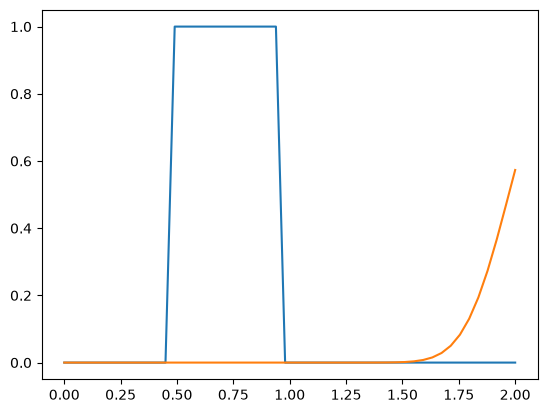

In [2]:
#solve of the 1D linear convection:
#du/dt + c du/dx = 0

#for time we use forward difference scheme
#for space we use backward difference scheme

#space mesh
domain = np.array([0, 2])
nx = 50
dx = (domain[1] - domain[0]) / (nx - 1)
x = np.linspace(domain[0], domain[1], nx)

#time steps
time_domain = np.array([0, 1.5])
dt = 0.025
t = np.arange(time_domain[0], time_domain[1], dt)
nt = len(t)

#declare constant c
c = 1

#declare initial conditions, hat function from x=0.5 a x=0.6
u = np.zeros(nx)
u[int(0.5/dx) : int(1/dx)] = 1

plt.plot(x, u)

#solve iterations

solutions: dict = {}

for n in range(nt):
    un = u.copy()
    solutions[t[n]] = un
    for i in range(1, nx):
        u[i] = un[i] - (c * (dt/dx) * (un[i] - un[i-1]))

plt.plot(x, u)




In [3]:
#define solution animation
fig, ax = plt.subplots(figsize=(8, 4))
ax.set_xlim(domain[0], domain[1])
ax.set_ylim(0, 1.5)
ax.set_title("1D Linear Convection Animation")
ax.set_xlabel("x")
ax.set_ylabel("u")

#empty line
(line,) = ax.plot([], [], lw=2, color='blue')

def init():
    line.set_data([], [])
    return (line,)

def update(frame):
    u = solutions[frame]  # Desloca a onda
    line.set_data(x, u)
    ax.set_title(
        f'1D Linear Convection (t = {frame:.2f} s)' if isinstance(frame, float)
        else "1D Linear Convection"
    )
    return (line,)  # Retorna os artistas modificados

anim = animation.FuncAnimation(
    fig=fig,
    func=update,
    frames=solutions.keys(),  # Quantidade total de frames (pode ser range, array, etc.)
    init_func=init,
    interval=30,  # Tempo entre frames em milissegundos (30ms ≈ 33 fps)
    blit=False,  # Otimiza a renderização redesenhando apenas o que mudou
)

anim.save('convection_1d.gif', writer='pillow', fps=20)
plt.close(fig)
print("Animação salva com sucesso!")

Animação salva com sucesso!


we can crearly see the numerical diffusion occuring